# Data Preprocessing — Phase 2, Module 02

This notebook explores common preprocessing steps using Pandas, NumPy, Matplotlib, and Scikit-learn.

**Learning goals**
- Inspect a dataset and identify missing values and duplicates.
- Impute missing values and encode categorical features.
- Scale numerical features and inspect potential outliers.
- Split data before fitting preprocessing transformations to avoid data leakage.
- Build a reusable `Pipeline` with a `ColumnTransformer`.

Keeping reusable implementations in the sibling `src/` or module-level `.py` files; using this notebook for exploration, visualizations, and notes.


## 1. Imports and load the sample dataset

Expected file location: `02-data-preprocessing/data/sample_data.csv`. The path helper below works when the notebook is saved in the module's `notebooks/` directory. If the CSV is elsewhere, update `DATA_PATH`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler

RANDOM_STATE = 42
DATA_PATH = Path("../data/sample_data.csv")

if not DATA_PATH.exists():
    # Fallback if the notebook is launched from the module root.
    DATA_PATH = Path("data/sample_data.csv")

df = pd.read_csv(DATA_PATH)
df.head()


,Age,Salary,Experience,City,Education
0,21.0,30000.0,1,Raipur,Bachelor
1,25.0,NaN,3,Delhi,Master
2,NaN,45000.0,5,Raipur,Bachelor
3,30.0,50000.0,8,Mumbai,Master
4,28.0,42000.0,4,Delhi,Bachelor


## 2. Inspect the data

Check dimensions, column types, summary statistics, missing values, and duplicate rows before transforming anything.

In [2]:
print("Shape:", df.shape)
display(df.info())
display(df.describe(include="all").T)

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})
display(missing_summary)
print("Duplicate rows:", df.duplicated().sum())


Shape: (10, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Age         9 non-null      float64
 1   Salary      9 non-null      float64
 2   Experience  10 non-null     int64  
 3   City        10 non-null     object 
 4   Education   10 non-null     object 
dtypes: float64(2), int64(1), object(2)
memory usage: 532.0+ bytes


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,9.0,NaN,NaN,NaN,28.888889,6.13279,21.0,25.0,28.0,32.0,40.0
Salary,9.0,NaN,NaN,NaN,50777.777778,19530.602767,30000.0,38000.0,45000.0,60000.0,90000.0
Experience,10.0,NaN,NaN,NaN,6.0,4.396969,1.0,3.0,4.5,8.75,15.0
City,10,3,Raipur,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,10,3,Bachelor,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_percent
Age,1,10.0
Salary,1,10.0
Experience,0,0.0
City,0,0.0
Education,0,0.0


Duplicate rows: 0


## 3. Handle missing values — demonstration

For this exploratory example, use the median for numerical columns and the most frequent value for categorical columns. In a model workflow, fit imputers on the training data only; the final pipeline below does this correctly.

In [3]:
df_exploration = df.copy()
numeric_cols = df_exploration.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_exploration.select_dtypes(exclude=np.number).columns.tolist()

for col in numeric_cols:
    df_exploration[col] = df_exploration[col].fillna(df_exploration[col].median())

for col in categorical_cols:
    mode = df_exploration[col].mode(dropna=True)
    if not mode.empty:
        df_exploration[col] = df_exploration[col].fillna(mode.iloc[0])

print("Missing values before:")
display(df.isna().sum())
print("Missing values after exploratory imputation:")
display(df_exploration.isna().sum())
df_exploration.head()


Missing values before:


Age           1
Salary        1
Experience    0
City          0
Education     0
dtype: int64

Missing values after exploratory imputation:


Age           0
Salary        0
Experience    0
City          0
Education     0
dtype: int64

,Age,Salary,Experience,City,Education
0,21.0,30000.0,1,Raipur,Bachelor
1,25.0,45000.0,3,Delhi,Master
2,28.0,45000.0,5,Raipur,Bachelor
3,30.0,50000.0,8,Mumbai,Master
4,28.0,42000.0,4,Delhi,Bachelor


## 4. Explore numerical distributions

Visualizations help reveal skew, unusual values, and differences in feature scales.

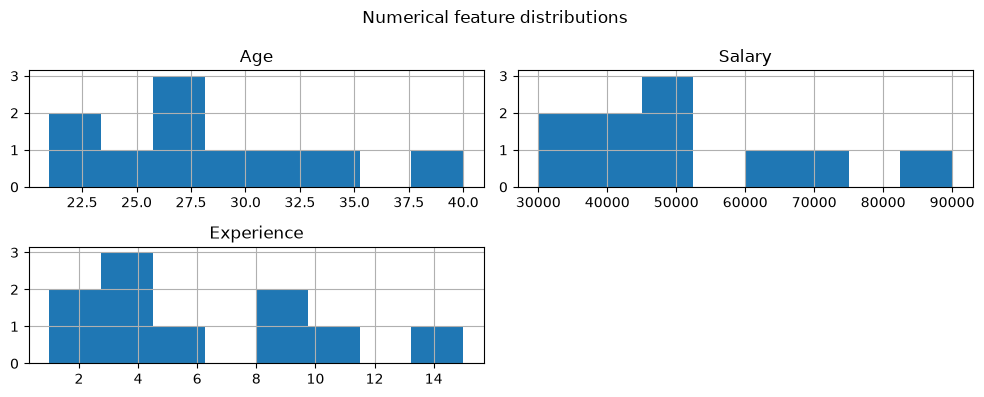

In [4]:
plot_cols = [col for col in ["Age", "Salary", "Experience"] if col in df_exploration.columns]
df_exploration[plot_cols].hist(figsize=(10, 4), bins=8)
plt.suptitle("Numerical feature distributions")
plt.tight_layout()
plt.show()


## 5. Detect potential outliers with IQR

The IQR rule flags values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`. A flagged value is not automatically an error and should not be removed without context.

Age: {'Q1': np.float64(25.0), 'Q3': np.float64(32.0), 'IQR': np.float64(7.0), 'lower_bound': np.float64(14.5), 'upper_bound': np.float64(42.5), 'outlier_count': 0, 'outlier_values': []}
Salary: {'Q1': np.float64(38000.0), 'Q3': np.float64(60000.0), 'IQR': np.float64(22000.0), 'lower_bound': np.float64(5000.0), 'upper_bound': np.float64(93000.0), 'outlier_count': 0, 'outlier_values': []}
Experience: {'Q1': np.float64(3.0), 'Q3': np.float64(8.75), 'IQR': np.float64(5.75), 'lower_bound': np.float64(-5.625), 'upper_bound': np.float64(17.375), 'outlier_count': 0, 'outlier_values': []}


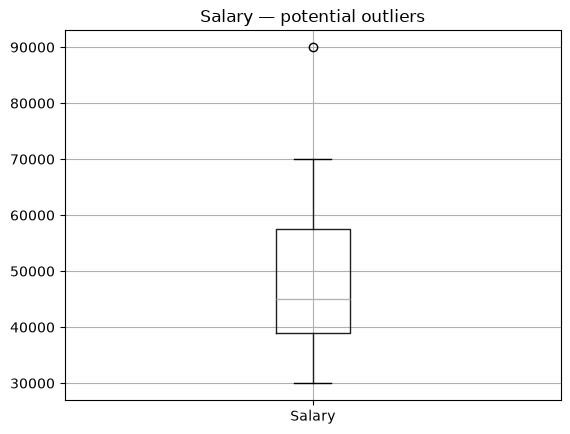

In [5]:
def iqr_outlier_report(series: pd.Series) -> dict:
    values = series.dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return {"Q1": q1, "Q3": q3, "IQR": iqr,
            "lower_bound": lower, "upper_bound": upper,
            "outlier_count": int(mask.sum()),
            "outlier_values": series[mask].tolist()}

for col in [c for c in ["Age", "Salary", "Experience"] if c in df.columns]:
    print(f"{col}: {iqr_outlier_report(df[col])}")

if "Salary" in df_exploration.columns:
    df_exploration.boxplot(column="Salary")
    plt.title("Salary — potential outliers")
    plt.show()


## 6. Encoding and scaling — small demonstrations

`get_dummies` is convenient for exploration. In reusable ML workflows, prefer a fitted `OneHotEncoder` inside a pipeline so the same feature mapping is applied at training and inference time.

In [6]:
if "City" in df_exploration.columns:
    display(pd.get_dummies(df_exploration["City"], prefix="City", dtype=int).head())

scale_cols = [c for c in ["Age", "Salary", "Experience"] if c in df_exploration.columns]
if scale_cols:
    demo_values = df_exploration[scale_cols]
    minmax_values = MinMaxScaler().fit_transform(demo_values)
    standard_values = StandardScaler().fit_transform(demo_values)
    print("Min-Max scaled (first 5 rows):")
    display(pd.DataFrame(minmax_values, columns=scale_cols).head())
    print("Standardized (first 5 rows):")
    display(pd.DataFrame(standard_values, columns=scale_cols).head())

print("Remember: these demonstrations fit on all rows only for visualization. Do not use this pattern to evaluate a model.")


,City_Delhi,City_Mumbai,City_Raipur
0,0,0,1
1,1,0,0
2,0,0,1
3,0,1,0
4,1,0,0


Min-Max scaled (first 5 rows):


,Age,Salary,Experience
0,0.000000,0.000000,0.000000
1,0.210526,0.250000,0.142857
2,0.368421,0.250000,0.285714
3,0.473684,0.333333,0.500000
4,0.368421,0.200000,0.214286


Standardized (first 5 rows):


,Age,Salary,Experience
0,-1.420296,-1.150703,-1.198658
1,-0.691939,-0.296221,-0.719195
2,-0.145671,-0.296221,-0.239732
3,0.218507,-0.011393,0.479463
4,-0.145671,-0.467117,-0.479463


Remember: these demonstrations fit on all rows only for visualization. Do not use this pattern to evaluate a model.


## 7. Build a leakage-safe preprocessing pipeline

For this example, `Salary` is the target. Rows with missing target values are removed because we cannot train a supervised model without known labels. We split the data first, then fit imputers, encoders, and scalers using training data only.

In [7]:
target = "Salary"
feature_cols = ["Age", "Experience", "City", "Education"]

model_df = df.dropna(subset=[target]).copy()
X = model_df[feature_cols]
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

numeric_features = ["Age", "Experience"]
categorical_features = ["City", "Education"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Training rows: 7
Testing rows: 2
Processed training shape: (7, 8)
Processed testing shape: (2, 8)


## 8. Self-check questions

Answer these in your own words before moving on:

1. Why might the median be preferable to the mean when a feature contains extreme values?
2. Why is one-hot encoding usually safer than assigning arbitrary integer labels to cities?
3. Which types of models are sensitive to feature scaling, and why?
4. Why should we not automatically delete every IQR-flagged observation?
5. What is data leakage, and how does splitting before fitting transformations prevent it?
6. What does `handle_unknown="ignore"` do when inference data contains a category not seen during training?
7. Why do we call `fit_transform` on training data but only `transform` on test data?

## Completion checklist

- [ ] I can explain each preprocessing technique.
- [ ] I inspected missing values and distributions.
- [ ] I understand that IQR flags candidates, not necessarily errors.
- [ ] I built and ran the leakage-safe preprocessing pipeline.
- [ ] I answered the self-check questions.

**Next module:** `03-supervised-learning/`.